# Noise: what survives on IBM's free-plan devices

`01_how_it_works` ran the detector on a perfect simulator. Here the same three
boards run on simulated copies ("fake backends") of the three devices on
IBM's free Open plan: **ibm_kingston, ibm_marrakesh and ibm_fez**. Each fake
backend holds a snapshot of the real device's calibration data and simulates
its gate errors, decay and readout errors.

Three levels of realism:

1. **Published-data model:** the device's calibration data gives the gate
   noise ε and the readout errors of the 3 line qubits (two per qubit: 0 read
   as 1, and 1 read as 0), which predict the counts in milliseconds.
2. **Noise-model simulator:** every gate error, T1/T2 decay and readout error
   simulated, with the detector calibrating in the same job, exactly as a
   hardware run would.
3. Real hardware: `03_hardware`.

Runs in a few minutes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from qttt.backends import IdealBackend, get_backend
from qttt.board import EMPTY, O, X, classical_winning_lines
from qttt.detector import DEFAULT_BUDGET, DEFAULT_SHOTS, NUM_LINES, detect_winners, flag_and_check
from qttt.noise import NoiseProfile

SEED = 4903
SHOTS = DEFAULT_SHOTS
BUDGET = DEFAULT_BUDGET
DEVICES = ("fake_kingston", "fake_marrakesh", "fake_fez")  # snapshots of the free-plan devices
VARIANT_NAMES = {"player": "12-qubit", "full": "22-qubit"}

_ = EMPTY
CASES = {
    "Single win": (X, O, X,
                   O, X, O,
                   _, _, X),
    "Double win": (X, X, X,
                   X, O, O,
                   X, O, O),
    "No win": (X, O, X,
               X, O, O,
               O, X, X),
}


def winning_lines(board):
    return classical_winning_lines(board, X) | classical_winning_lines(board, O)


def cases_for(variant):
    """(board, player) pairs; X just moved on all three boards."""
    return [(board, X if variant == "player" else None) for board in CASES.values()]


def plot_counts(ax, counts, board, cutoffs, title):
    """Green: real winning lines. Orange: flagged but rejected. Black ticks: each line's cutoff."""
    winners = winning_lines(board)
    verdict = flag_and_check(board, counts, cutoffs)
    colors = ["tab:green" if i in winners else "tab:orange" if i in verdict.rejected else "tab:gray"
              for i in range(NUM_LINES)]
    shots = sum(counts)
    ax.bar(range(NUM_LINES), [c / shots for c in counts], color=colors)
    ax.hlines([k / shots for k in cutoffs], [i - 0.4 for i in range(NUM_LINES)],
              [i + 0.4 for i in range(NUM_LINES)], color="black", linewidth=1.5)
    ax.axhline(1 / 8, color="gray", linestyle=":", linewidth=1)
    ax.set_xticks(range(NUM_LINES))
    ax.set_ylim(0, 1)
    text = f"{verdict.winner} wins, lines {sorted(verdict.lines)}" if verdict.winner else "no winner"
    ax.set_title(f"{title}\n{text}, checks: {len(verdict.candidates)}", fontsize=9)


def plot_grid(columns, suptitle):
    """columns: {column title: (cutoffs, {case name: counts})}"""
    fig, axes = plt.subplots(len(CASES), len(columns), figsize=(3.2 * len(columns), 2.8 * len(CASES)),
                             squeeze=False, sharey=True)
    for c, (col, (cutoffs, by_case)) in enumerate(columns.items()):
        for r, (name, board) in enumerate(CASES.items()):
            plot_counts(axes[r][c], by_case[name], board, cutoffs, col if r == 0 else "")
            if c == 0:
                axes[r][c].set_ylabel(f"{name}\nfraction of shots")
            if r == len(CASES) - 1:
                axes[r][c].set_xlabel("line index")
    fig.suptitle(suptitle)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.legend(handles=[Patch(color="tab:green", label="winning line"), Patch(color="tab:gray", label="losing line"),
                        Patch(color="tab:orange", label="flagged, rejected by the check"),
                        Line2D([], [], color="black", linewidth=1.5, label="cutoff"),
                        Line2D([], [], color="gray", linestyle=":", label="1/8 (even spread)")],
               loc="lower center", ncol=5, fontsize=8, frameon=False)
    return fig

## The devices

Each version of the circuit is compiled once per device (5 compiler seeds,
best kept). The 12-qubit circuit is compiled with and without the ancilla
qubit and the one with the higher ESP is kept, so the choice can differ by
device. ESP, the estimated success probability, multiplies (1 − error)
over every gate: roughly the chance that no gate fails.

In [2]:
backends = {name.removeprefix("fake_"): get_backend(name, seed=SEED, transpile_seeds=5) for name in DEVICES}
print(f"{'device':10} {'calibration':11} {'2q gates 12 / 22':>17} {'ancilla':>7} {'ESP 12':>7} {'ESP 22':>8}")
for label, backend in backends.items():
    m12 = backend.metrics(backend.search_template("player"))
    m22 = backend.metrics(backend.search_template("full"))
    print(f"{label:10} {backend.calibration_date()[:10]:11} {f'{m12.two_qubit_gates} / {m22.two_qubit_gates}':>17}"
          f" {'yes' if m12.ancilla else 'no':>7} {10 ** m12.log10_esp:>7.1%} {10 ** m22.log10_esp:>8.1e}")

device     calibration  2q gates 12 / 22 ancilla  ESP 12   ESP 22


kingston   2026-04-15         406 / 2765     yes   51.1%  2.8e-03


marrakesh  2025-02-26         458 / 2784      no   31.2%  2.5e-04


fez        2025-02-26         406 / 2765     yes   24.2%  1.5e-05


## 1. Published-data model

`NoiseProfile.from_backend` builds a profile from the calibration data:

- **Gate noise:** ε = 1 − ESP, the share of shots that gate errors scatter
  evenly over the 8 lines.
- **Readout:** each of the 3 line qubits misreads 0 as 1 or 1 as 0 with its own
  probability; together they form an 8×8 readout matrix A.

Predicted counts = A · [(1 − ε) · ideal + ε / 8]. The profile gives each line
its own cutoff (lines that readout bias pushes up need more counts) and
predicts how often wins are missed. Below, 1024 shots are drawn from each
prediction and scored like a real run.

**Reading the bar charts:** each bar is the fraction of shots measured on a
line index. Green: the board's real winning lines. Gray: losing lines.
Orange: a losing line that reached its cutoff, so it was flagged and then
rejected by the classical check. The black tick on each bar is that line's
cutoff (lines get their own cutoffs from the noise profile), and the dotted
line is 1/8, an even spread over all 8 lines.

version  device          ε  worst miss at 1024 shots  shots for ≤1% misses
12-qubit kingston    0.489                     0.00%  64
12-qubit marrakesh   0.688                     0.00%  192
12-qubit fez         0.758                     0.00%  256


22-qubit kingston    0.997                    98.49%  more than 16384


22-qubit marrakesh   1.000                    98.96%  more than 16384


22-qubit fez         1.000                    99.00%  more than 16384


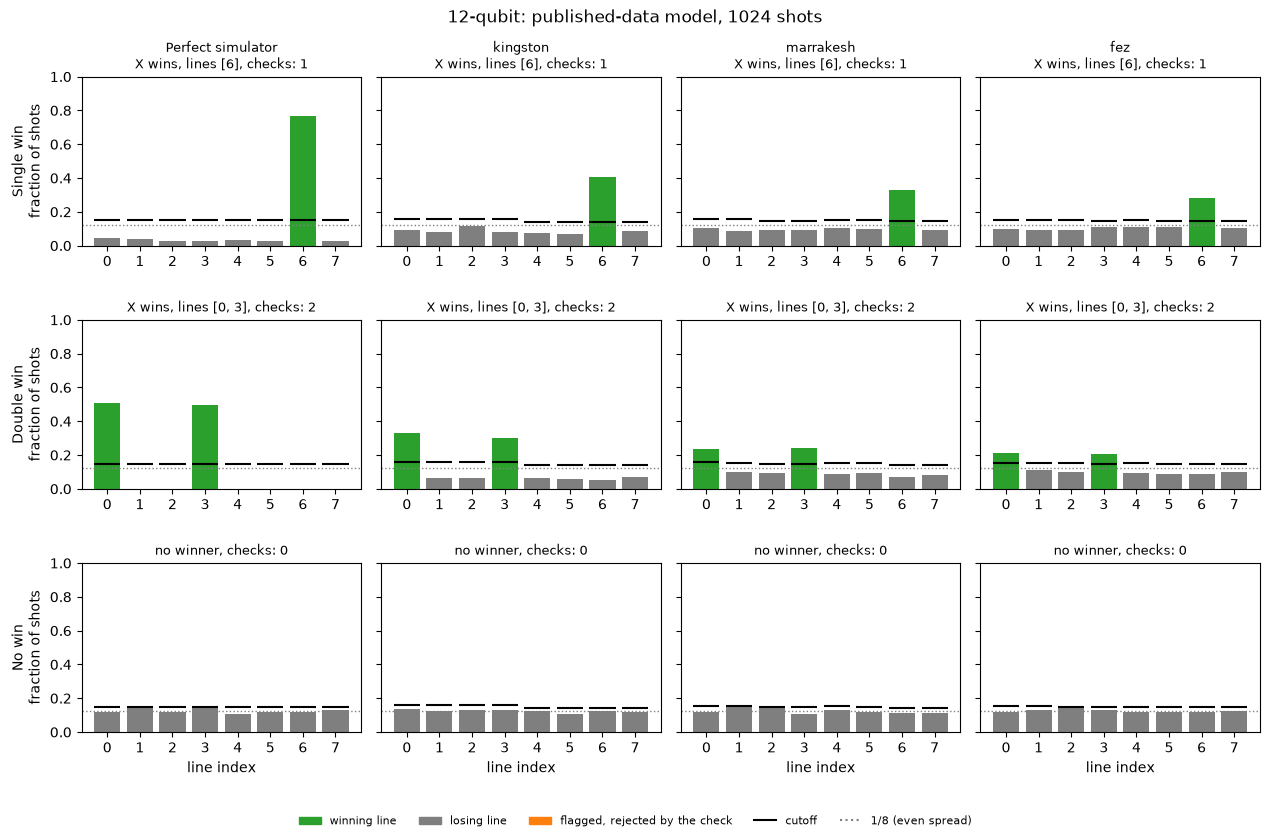

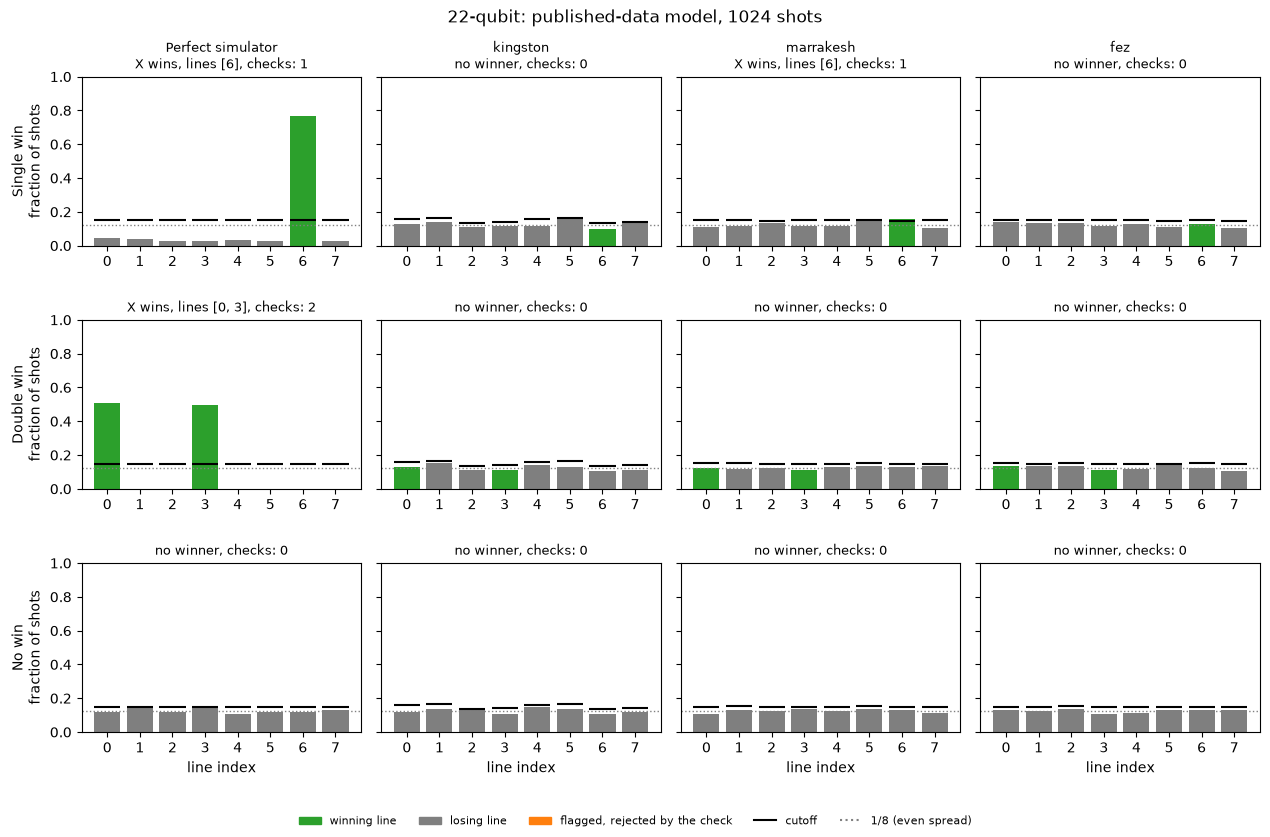

In [3]:
rng = np.random.default_rng(SEED)
ideal_cutoffs = NoiseProfile.from_ideal().cutoffs(SHOTS, BUDGET)
published = {v: {label: NoiseProfile.from_backend(b, v) for label, b in backends.items()} for v in VARIANT_NAMES}

print(f"{'version':8} {'device':10} {'ε':>6}  {'worst miss at 1024 shots':>24}  shots for ≤1% misses")
for variant in VARIANT_NAMES:
    for label, profile in published[variant].items():
        needed = profile.shots_needed(0.01, BUDGET)
        print(f"{VARIANT_NAMES[variant]:8} {label:10} {profile.epsilon:>6.3f}  "
              f"{profile.miss_rates(SHOTS, BUDGET).worst:>24.2%}  {needed or 'more than 16384'}")

ideal_counts = {name: r.run.counts for name, r in zip(
    CASES, detect_winners(cases_for("player"), shots=SHOTS, backend=IdealBackend(seed=SEED)))}
for variant in VARIANT_NAMES:
    columns = {"Perfect simulator": (ideal_cutoffs, ideal_counts)}
    for label, profile in published[variant].items():
        drawn = {}
        for name, board in CASES.items():
            p = np.array(profile.predicted_for(winning_lines(board)))
            drawn[name] = tuple(int(c) for c in rng.multinomial(SHOTS, p / p.sum()))
        columns[label] = (profile.cutoffs(SHOTS, BUDGET), drawn)
    plot_grid(columns, f"{VARIANT_NAMES[variant]}: published-data model, {SHOTS} shots")
    plt.show()

The 22-qubit circuit needs thousands of two-qubit gates, so gate noise erases
the signal on every device: every line sits near 12.5% and wins are missed.
The 12-qubit circuit needs a few hundred, and enough signal survives on all three.

## 2. Noise-model simulator, calibrating in the same job

`detect_winners` with its default settings, exactly as on real hardware: one
job holds the 8 readout-calibration circuits (each line index prepared
directly on the line qubits), a board with a known winner, and the three
boards. When the job is back, the readout matrix and ε are fitted from the
calibration circuits and the cutoffs are set from them. About a minute per
device.

kingston: measured ε 0.793, cutoffs (155, 155, 152, 151, 152, 150, 155, 156)
    Single win  (95, 105, 119, 99, 112, 126, 264, 104)  winner X  rejected []
    Double win  (215, 115, 129, 190, 93, 88, 87, 107)  winner X  rejected []
    No win      (131, 134, 137, 108, 104, 128, 152, 130)  winner None  rejected []


marrakesh: measured ε 0.930, cutoffs (153, 153, 155, 152, 154, 152, 152, 155)
    Single win  (119, 125, 142, 113, 108, 138, 150, 129)  winner None  rejected []
    Double win  (171, 113, 138, 133, 122, 122, 106, 119)  winner X  rejected []
    No win      (120, 119, 152, 136, 140, 123, 113, 121)  winner None  rejected []


fez: measured ε 0.867, cutoffs (153, 153, 154, 153, 153, 152, 153, 153)
    Single win  (135, 98, 137, 122, 123, 129, 162, 118)  winner X  rejected []
    Double win  (189, 131, 128, 165, 107, 108, 105, 91)  winner X  rejected []
    No win      (126, 125, 139, 139, 113, 132, 129, 121)  winner None  rejected []


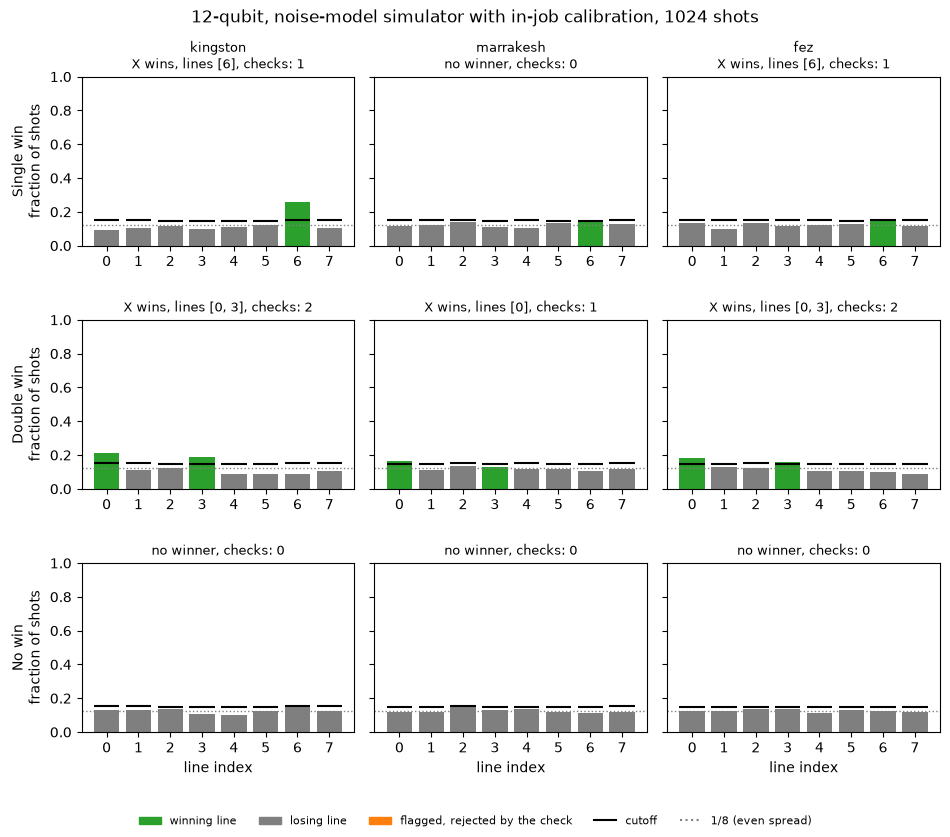

In [4]:
measured = {}
simulated = {}
for label, backend in backends.items():
    results = detect_winners(cases_for("player"), shots=SHOTS, budget=BUDGET, backend=backend)
    measured[label] = results[0].profile
    simulated[label] = (results[0].cutoffs, {name: r.run.counts for name, r in zip(CASES, results)})
    print(f"{label}: measured ε {measured[label].epsilon:.3f}, cutoffs {results[0].cutoffs}")
    for name, r in zip(CASES, results):
        print(f"    {name:11} {r.run.counts}  winner {r.winner}  rejected {list(r.rejected)}")
plot_grid(simulated, f"12-qubit, noise-model simulator with in-job calibration, {SHOTS} shots")
plt.show()

## 3. Published vs measured noise

The measured ε and 1 − ESP are close but not equal, and which is larger
depends on the device. ESP treats every gate error as ruining the whole
result, which is pessimistic, but it leaves out qubit decay during the gates,
which the simulator includes. Published readout errors can also
describe a bias the device does not have, which sets the per-line cutoffs on
the wrong lines. Measuring both in the same job avoids that, and it works on
any provider, including ones that publish nothing.

device     ε published ε measured  shots for ≤1% misses (published / measured)


kingston         0.489      0.793  64 / 320


marrakesh        0.688      0.930  192 / 2240


fez              0.758      0.867  256 / 640


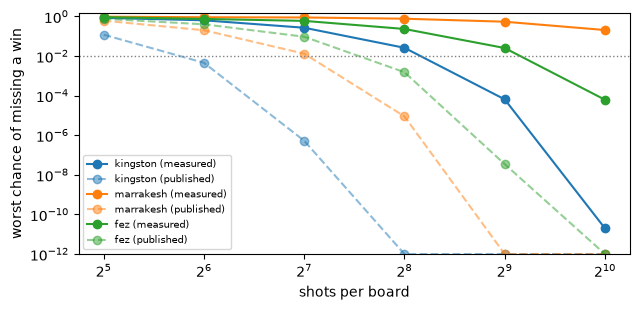

In [5]:
print(f"{'device':10} {'ε published':>11} {'ε measured':>10}  shots for ≤1% misses (published / measured)")
for label in backends:
    p, m = published["player"][label], measured[label]
    print(f"{label:10} {p.epsilon:>11.3f} {m.epsilon:>10.3f}  {p.shots_needed(0.01, BUDGET)} / {m.shots_needed(0.01, BUDGET)}")

shot_counts = [32, 64, 128, 256, 512, 1024]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for (label, profile), color in zip(measured.items(), ("tab:blue", "tab:orange", "tab:green")):
    worst = [max(profile.miss_rates(n, BUDGET).worst, 1e-12) for n in shot_counts]
    ax.plot(shot_counts, worst, "o-", color=color, label=f"{label} (measured)")
    worst_p = [max(published["player"][label].miss_rates(n, BUDGET).worst, 1e-12) for n in shot_counts]
    ax.plot(shot_counts, worst_p, "o--", color=color, alpha=0.5, label=f"{label} (published)")
ax.axhline(0.01, color="gray", linestyle=":", linewidth=1)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_ylim(1e-12, 1.5)
ax.set_xlabel("shots per board")
ax.set_ylabel("worst chance of missing a win")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

**Reading the results:** on all three free-plan devices the 12-qubit detector
finds every single and double win with 1024 shots, and the profiles say far
fewer shots would do. A flagged losing line (orange) is always rejected by the
classical check, so noise never produces a wrong winner. These are simulations
of calibration snapshots; `03_hardware` tests the real devices.